# 게이트가 있는 프롬프트 체이닝

**이 노트북에서 할 일**

1. OpenAI SDK로 요청을 한 번 직접 보내고, 받은 JSON 글을 딕셔너리로 읽습니다.
2. 요청마다 기록 한 줄을 남기는 함수와, 기획을 검사하는 게이트 함수를 만듭니다.
3. 게이트 없이 두 단계를 이으면 약속과 다른 기획이 끝까지 흘러가는 것을 봅니다(Before).
4. 두 단계 사이에 게이트를 두어 둘째 요청을 보내기 전에 멈춥니다(After).

**준비물** — 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
모델 `gpt-5.4-mini`에 보내는 요청은 노트북 한 번에 여섯 번입니다.
4절에서 한 번, 9절에서 두 번, 10절에서 세 번 나갑니다.

토큰 수를 출력하는 요청은 여섯 번 가운데 네 번입니다.
나머지 요청도 같은 크기로 보고 요금표를 곱해 어림한 예상 비용은 미화 0.01달러 아래입니다.
실제 청구 금액과는 다를 수 있습니다.

읽는 파일과 새로 쓰는 파일은 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 20초 안에 끝났습니다.

**기준 버전** — 첫 셀에서 openai 2.29.0과 python-dotenv 1.2.3을 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~8절을 읽습니다.
요청 한 번의 모양과 기록, 게이트 함수를 익히는 자리입니다.
9~11절은 두 단계를 게이트 없이, 그리고 게이트와 함께 이어 보는 자리입니다.
이 부분은 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch18-workflow-patterns`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 초록 상자 기획 요청 글 칸 셋 제목 독자 절차를 약속함에서 보라 상자 gpt-5.4-mini 첫 단계 기획으로, 다시 노란 상자 중간 결과 기획 딕셔너리 칸 셋으로, 다시 파란 상자 게이트 check_plan 필수 칸 셋과 절차 셋 이상으로 이어지고, 게이트에서 점선 둘이 나뉘어 문제 없음이면 보라 상자 gpt-5.4-mini 둘째 단계 작성을 지나 노란 상자 상태 완료 안내문으로 가고 문제 있음이면 노란 상자 상태 멈춤 문제 목록 작성 요청 없음으로 가는 그림](attachment:01-1-단계-잇기와-게이트.png)

위에서 아래로 읽습니다. 초록 요청 글이 보라 첫 단계 모델을 지나 노란 중간 결과가 됩니다.
파란 게이트에서 점선이 둘로 나뉩니다. 문제가 없을 때만 보라 둘째 단계 모델로 갑니다.
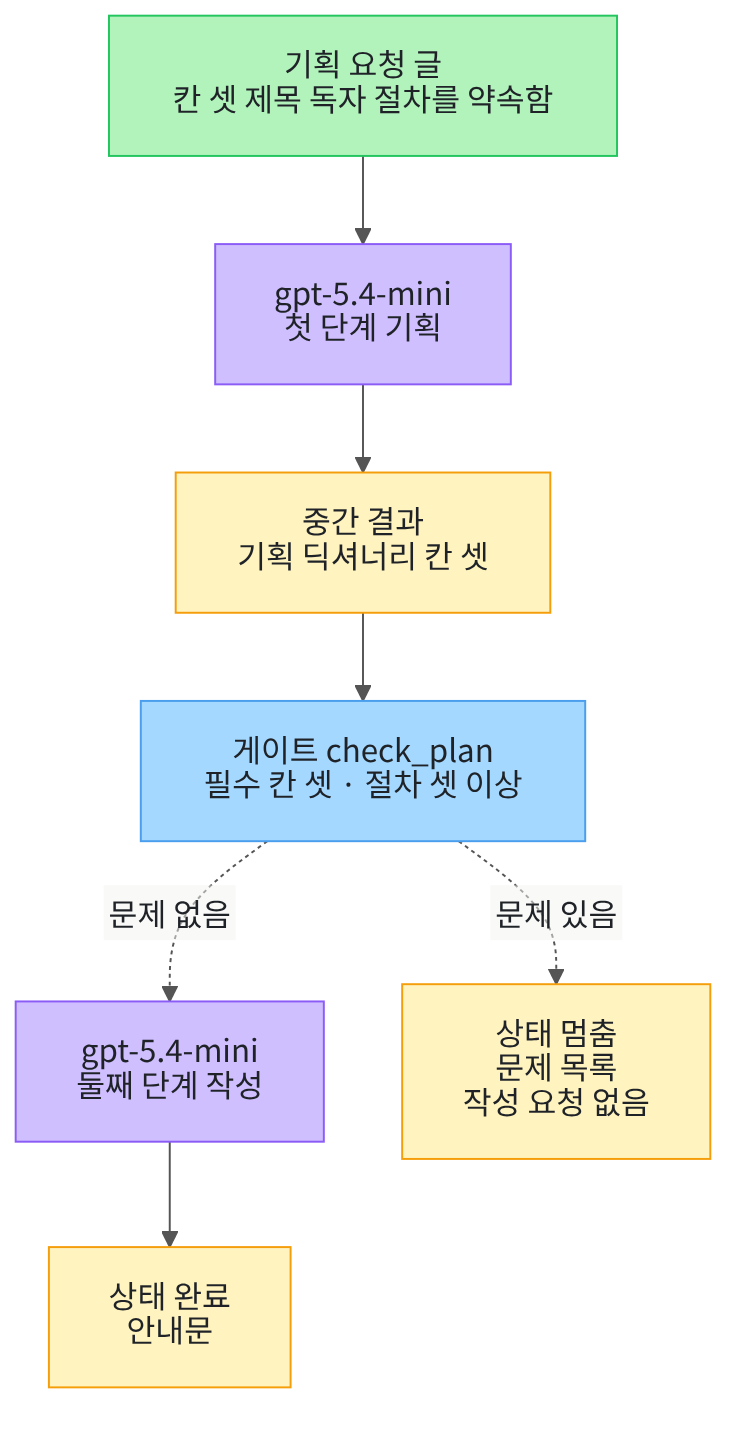

## 1. 준비

제목의 프롬프트 체이닝(prompt chaining)은 모델 요청 여러 개를 정해 둔 차례로 잇는 모양입니다.
이 챕터는 이 모양을 「단계 잇기」라고 부릅니다.

Ch 6부터 Ch 17까지는 LangChain의 `init_chat_model`로 모델을 불렀습니다.
이 챕터는 OpenAI가 낸 파이썬 패키지(SDK)를 직접 씁니다.
다섯 모양의 흐름을 프레임워크 없이 코드로 적어 보려는 까닭입니다.

첫 셀은 패키지 두 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "openai==2.29.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
openai: 2.29.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `openai: 2.29.0`과 `python-dotenv: 1.2.3`이 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-23에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름 둘을 불러옵니다.
패키지 `openai`에서는 클라이언트를 만드는 이름 `OpenAI`를 가져옵니다.

In [2]:
# 모델 글을 딕셔너리로 읽을 json과, OpenAI 서비스에 요청을 보낼 클라이언트 이름을 불러옵니다
import json

from openai import OpenAI

print("불러온 이름:", "json", "OpenAI")

불러온 이름: json OpenAI


**결과 읽기** — 출력 줄 `불러온 이름: json OpenAI`로 이름 둘을 불러왔습니다.

## 2. 키와 클라이언트 준비

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄 `OPENAI_API_KEY 설정 여부: True`로 키를 찾았습니다.
키 값은 출력하지 않습니다.

클라이언트(client)는 서비스에 요청을 보내고 응답을 받는 파이썬 객체입니다.
주문을 받아 전해 주는 접수 창구와 같습니다.
이 절에서는 `client = OpenAI()` 한 줄로 만들고, 요청은 메서드 `client.responses.create`로 보냅니다.

괄호 안을 비워 두면 키는 환경 변수 `OPENAI_API_KEY`에서 읽습니다.
앞 셀의 `load_dotenv`가 `.env`의 키를 환경 변수로 올려 두었습니다.

In [4]:
# OpenAI 서비스에 요청을 보낼 클라이언트를 만듭니다(키는 앞 셀에서 읽은 환경 변수를 씁니다)
client = OpenAI()
print("클라이언트:", type(client).__name__)
print("실패한 요청을 다시 보내는 횟수(기본값):", client.max_retries)

클라이언트: OpenAI
실패한 요청을 다시 보내는 횟수(기본값): 2


**결과 읽기** — 출력 줄 `클라이언트: OpenAI`로 클라이언트를 만들었습니다.
출력 줄 `실패한 요청을 다시 보내는 횟수(기본값): 2`는 SDK의 기본값입니다.
연결이 끊기거나 서비스가 일부 오류를 내면 SDK가 그 요청을 두 번까지 다시 보냅니다.
이 동작은 설치한 2.29.0 판 소스에서 확인했습니다.
이번 실행에서 다시 보낸 적이 있는지는 보지 않았습니다.

## 3. 지시 글과 요청 글

모델에게 보내는 글은 두 칸으로 나뉩니다.
지시 글(instructions)은 요청 글보다 먼저 모델에게 주는 역할과 규칙 글입니다.
SDK 설명은 이 글이 시스템(또는 개발자) 메시지로 들어간다고 적습니다.
Ch 16 01절의 시스템 메시지와 같은 구실입니다.

요청 글(input)은 Ch 15·Ch 17에서처럼 이번에 할 일을 적은 글입니다.
이 절의 두 단계는 지시 글 하나를 함께 쓰고 요청 글만 바꿉니다.
첫 단계 요청 글에는 기획의 칸 셋 「제목」·「독자」·「절차」를 약속해 둡니다.

In [5]:
# 두 단계에 함께 쓸 지시 글과, 첫 단계(기획)에 보낼 요청 글을 적습니다
instructions_text = "고객 지원 안내문을 만드는 작성자입니다. 한국어로 쓰고, 답은 JSON 객체 하나로만 출력합니다."
# 요청 글에는 기획의 칸 셋과 절차 수를 약속해 둡니다
plan_request = "비밀번호 재설정 안내문을 쓰기 전에 기획을 적어 주세요.\n"
plan_request = plan_request + "「절차」에는 고객이 따라 할 재설정 순서를 셋 이상 적습니다.\n"
plan_request = plan_request + 'JSON만 출력하세요: {"제목": "글", "독자": "글", "절차": ["글", "글", "글"]}'
print("지시 글:", instructions_text)
print("기획 요청 글:")
print(plan_request)

지시 글: 고객 지원 안내문을 만드는 작성자입니다. 한국어로 쓰고, 답은 JSON 객체 하나로만 출력합니다.
기획 요청 글:
비밀번호 재설정 안내문을 쓰기 전에 기획을 적어 주세요.
「절차」에는 고객이 따라 할 재설정 순서를 셋 이상 적습니다.
JSON만 출력하세요: {"제목": "글", "독자": "글", "절차": ["글", "글", "글"]}


**결과 읽기** — 출력 줄 `지시 글:` 뒤가 두 단계에 함께 쓸 지시 글입니다.
라벨 줄 `기획 요청 글:` 아래 세 줄이 첫 단계 요청 글입니다.
둘째 줄에 칸 「절차」는 셋 이상이라고 적었습니다.
셋째 줄은 답의 모양을 JSON 글 하나로 보여 줍니다.

## 4. SDK로 요청 한 번 보내기

다음 셀은 첫 단계(기획) 요청을 SDK로 한 번 직접 보냅니다.
이 셀에서 모델 요청이 한 번 나갑니다.

메서드 `client.responses.create`는 응답 만들기 요청(Responses API)을 보내고 응답 객체를 내놓습니다.
인자 `model`에는 모델 이름을 적습니다.
인자 `temperature=0`과 `reasoning={"effort": "none"}`은 Ch 6부터 쓴 설정과 같은 뜻입니다.
인자 `instructions`와 `input`에는 지시 글과 요청 글을 넣습니다.

인자 `text`의 형식 `json_object`는 답을 JSON 글 하나로만 쓰게 합니다.
SDK 설명에 따르면 이 형식을 쓸 때는 JSON으로 답하라는 말을 글에 적어야 합니다.
이 절의 지시 글과 요청 글에는 모두 그 말이 있습니다.
서비스가 이 말을 지시 글이 아니라 요청 글에서 찾는다는 것은 02절에서 봅니다.

In [6]:
# 기획 요청을 SDK로 한 번 직접 보내 응답 객체를 받습니다(모델 요청 1번)
first_response = client.responses.create(
    # 모델 이름과 설정: temperature 0, 추론 none
    model="gpt-5.4-mini", temperature=0, reasoning={"effort": "none"},
    # 지시 글과 요청 글, 그리고 답을 JSON 글로만 받는 형식
    instructions=instructions_text, input=plan_request,
    text={"format": {"type": "json_object"}},
)
print("응답한 모델:", first_response.model)
print("temperature:", first_response.temperature)
print("추론 설정:", first_response.reasoning.effort)

응답한 모델: gpt-5.4-mini-2026-03-17
temperature: 0.0
추론 설정: none


**결과 읽기** — 출력 줄 `응답한 모델: gpt-5.4-mini-2026-03-17`은 서비스가 응답에 적어 보낸 모델 이름입니다.
끝에 날짜가 붙은 이름은 그 모델의 판 이름입니다.
출력 줄 `temperature: 0.0`과 `추론 설정: none`으로 서비스가 두 설정을 받아들였습니다.
이 노트북의 출력은 2026-09-23에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도 답 문장이 매번 같다고 보장하지는 않습니다.

다음 셀은 응답 객체에서 모델이 쓴 글과 토큰 수를 꺼냅니다.
속성 `output_text`는 모델이 쓴 글을 글 하나로 모은 값입니다.
속성 `usage`에는 입력 토큰 수와 출력 토큰 수가 들어 있습니다.

In [7]:
# 응답 객체에서 모델이 쓴 글과 토큰 수를 꺼내 봅니다
print("모델이 쓴 글:")
print(first_response.output_text)
print("입력 토큰:", first_response.usage.input_tokens)
print("출력 토큰:", first_response.usage.output_tokens)

모델이 쓴 글:
{"제목":"비밀번호 재설정 안내문 기획","독자":"비밀번호를 잊었거나 계정 보안을 위해 비밀번호를 변경하려는 고객","절차":["로그인 화면에서 '비밀번호 찾기' 또는 '비밀번호 재설정'을 선택합니다.","가입 시 등록한 이메일 주소 또는 휴대폰 번호를 입력해 본인 확인을 진행합니다.","전송된 인증번호 또는 확인 링크를 통해 본인 인증을 완료합니다.","새 비밀번호를 입력하고, 보안을 위해 한 번 더 확인 입력한 뒤 저장합니다.","재설정이 완료되면 새 비밀번호로 다시 로그인합니다."]}
입력 토큰: 108
출력 토큰: 144


**결과 읽기** — 라벨 줄 `모델이 쓴 글:` 아래 한 줄이 모델이 쓴 JSON 글입니다.
출력 줄 `입력 토큰: 108`은 지시 글과 요청 글을 모델에 넣을 때 센 토큰 수입니다.

출력 줄 `출력 토큰:` 뒤 수는 모델이 쓴 글의 길이라 실행마다 달라질 수 있습니다.
교재 출력에서는 `출력 토큰: 144`였습니다.

다음 셀은 받은 JSON 글을 `json.loads`로 딕셔너리로 읽습니다.
Ch 15 02절과 Ch 17 03절에서 쓴 방법입니다.
함수 `list`는 딕셔너리의 칸 이름을 목록으로 모읍니다.

In [8]:
# 받은 JSON 글을 딕셔너리로 읽고 칸 이름과 절차 수를 봅니다
first_plan = json.loads(first_response.output_text)
plan_keys = list(first_plan.keys())
print("칸 이름:", plan_keys)
print("절차 수:", len(first_plan["절차"]))

칸 이름: ['제목', '독자', '절차']
절차 수: 5


**결과 읽기** — 출력 줄 `칸 이름: ['제목', '독자', '절차']`로 약속한 칸 셋이 모두 왔습니다.

출력 줄 `절차 수:` 뒤 수도 모델이 쓴 기획에 따라 실행마다 달라질 수 있습니다.
교재 출력에서는 `절차 수: 5`로, 요청 글이 약속한 셋 이상이었습니다.

## 5. 기록 한 줄 남기기

이 챕터는 모델 요청 한 번마다 기록 한 줄을 남깁니다.
기록 한 줄은 칸 셋 「단계」·「입력 토큰」·「출력 토큰」을 가진 딕셔너리입니다.
기록 목록은 그 줄을 요청한 차례대로 모은 목록입니다.
요청 수는 기록 목록의 줄 수로 셉니다.

Ch 17의 실행 기록은 도구 단계와 멈춤까지 단계 하나를 한 줄로 적었습니다.
이 챕터의 기록 한 줄은 그와 달리 모델 요청 한 번입니다.

In [9]:
# 요청 한 번의 기록 한 줄(단계 이름·입력 토큰·출력 토큰)을 기록 목록 끝에 더합니다
def add_record(records, step_name, usage):
    row = {"단계": step_name}
    row["입력 토큰"] = usage.input_tokens
    row["출력 토큰"] = usage.output_tokens
    records.append(row)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `add_record`는 기록 목록과 단계 이름, 응답의 `usage`를 받습니다.
줄 딕셔너리를 만들어 목록 끝에 `append`로 더합니다.
아무 값도 내놓지 않고, 받은 목록 자체가 한 줄 길어집니다.

다음 셀은 기록 목록을 새로 만들고 4절 응답을 첫 줄로 남깁니다.

In [10]:
# 기록 목록을 새로 만들고, 4절에서 받은 응답을 「기획」 줄로 남깁니다
records = []
add_record(records, "기획", first_response.usage)
print("기록 줄 수:", len(records))
print("첫 줄:", records[0])

기록 줄 수: 1
첫 줄: {'단계': '기획', '입력 토큰': 108, '출력 토큰': 144}


**결과 읽기** — 출력 줄 `기록 줄 수: 1`로 한 줄이 생겼습니다.
출력 줄 `첫 줄:` 뒤 딕셔너리의 칸 `'단계': '기획'`이 이 줄의 단계 이름입니다.

다음 셀은 기록 목록을 표 모양으로 출력하는 함수입니다.

In [11]:
# 기록 목록을 줄마다 번호·단계·입력 토큰·출력 토큰 차례로 출력합니다
def print_records(records):
    print("번호 | 단계 | 입력 토큰 | 출력 토큰")
    for i in range(len(records)):
        row = records[i]
        print(i + 1, "|", row["단계"], "|", row["입력 토큰"], "|", row["출력 토큰"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `print_records`는 라벨 줄 하나를 먼저 출력합니다.
그다음 줄마다 번호와 세 칸을 세로줄로 나눠 출력합니다.
번호는 `i + 1`이라 1부터 셉니다.

In [12]:
# 지금까지의 기록을 표 모양으로 봅니다
print_records(records)

번호 | 단계 | 입력 토큰 | 출력 토큰
1 | 기획 | 108 | 144


**결과 읽기** — 라벨 줄 `번호 | 단계 | 입력 토큰 | 출력 토큰` 아래 한 줄이 4절 요청의 기록입니다.
줄 앞부분 `1 | 기획 | 108`이 번호와 단계, 입력 토큰입니다.

## 6. 요청 도움 함수

4절에서는 요청 하나에 인자 여섯을 적었습니다.
요청마다 같은 설정을 다시 적고 기록도 따로 남기면 빠뜨리기 쉽습니다.
그래서 요청 한 번과 기록 한 줄, JSON 읽기를 함수 하나로 묶습니다.
이 함수는 4절 셀과 같은 인자로 요청을 보냅니다.

In [13]:
# 요청을 한 번 보내 기록 한 줄을 남기고, 받은 JSON 글을 딕셔너리로 읽어 내놓습니다(모델 요청 1번)
def ask_json(client, records, step_name, instructions_text, request_text):
    response = client.responses.create(
        # 모델 이름과 설정: temperature 0, 추론 none(4절 직접 요청과 같음)
        model="gpt-5.4-mini", temperature=0, reasoning={"effort": "none"},
        # 지시 글과 요청 글, 그리고 답을 JSON 글로만 받는 형식
        instructions=instructions_text, input=request_text,
        text={"format": {"type": "json_object"}},
    )
    add_record(records, step_name, response.usage)
    return json.loads(response.output_text)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `ask_json`은 클라이언트와 기록 목록, 단계 이름, 지시 글, 요청 글을 받습니다.
요청을 보낸 뒤 5절 함수 `add_record`로 기록 한 줄을 남깁니다.
마지막으로 받은 JSON 글을 딕셔너리로 읽어 내놓습니다.
이 함수는 9절과 10절의 두 단계 흐름 안에서 처음 불립니다.

## 7. 게이트 만들기

중간 결과(intermediate output)는 앞 단계가 내놓아 다음 단계 요청 글에 들어갈 값입니다.
이 절에서는 첫 단계 모델이 내놓은 기획 딕셔너리입니다.

게이트(gate)는 중간 결과가 다음 단계에 쓸 모양인지 코드로 검사하는 자리입니다.
가마에 넣기 전에 금 간 그릇을 골라내는 일과 같습니다.
이 절의 게이트는 필수 칸이 모두 있는지, 칸 「절차」가 정한 수 이상의 목록인지 봅니다.
문제를 글 목록으로 내놓고, 문제가 없으면 빈 목록을 내놓습니다.

In [14]:
# 게이트: 기획이 다음 단계에 쓸 모양인지 코드로 검사해 문제를 글 목록으로 내놓습니다(문제가 없으면 빈 목록)
def check_plan(plan, required_keys, min_count):
    problems = []
    for key in required_keys:
        if key not in plan:
            problems.append(key + " 칸 없음")
    # 칸 「절차」가 있으면 목록인지, 목록이면 정한 수 이상인지 봅니다(or는 앞이 참이면 뒤를 보지 않음)
    if "절차" in plan and (type(plan["절차"]) != list or len(plan["절차"]) < min_count):
        problems.append("절차가 " + str(min_count) + "개 이상인 목록이 아님")
    return problems

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `check_plan`은 기획과 필수 칸 목록, 최소 절차 수를 받습니다.
필수 칸마다 `not in`으로 기획에 그 칸이 없는지 봅니다.

조건 `type(plan["절차"]) != list`는 칸 「절차」가 목록이 아닐 때 참입니다.
그 뒤 `or`로 이은 조건은 목록 길이가 최소 절차 수보다 작을 때 참입니다.
둘 가운데 하나라도 참이면 문제 하나를 더합니다.
파이썬 말 `or`는 앞 조건이 참이면 뒤 조건을 보지 않아, 목록이 아닌 값의 길이는 세지 않습니다.

맨 앞의 `"절차" in plan and`는 칸 「절차」가 있는지 먼저 봅니다.
파이썬 말 `and`는 앞 조건이 거짓이면 뒤 조건을 보지 않습니다.
그래서 칸 「절차」가 없는 기획에서는 `plan["절차"]`를 읽지 않습니다.
없는 칸을 대괄호로 읽으면 `KeyError`로 멈추며, 이 오류는 02절에서 실제로 봅니다.

다음 셀은 손으로 적은 기획 둘로 게이트를 확인합니다.
모델 글이 아니라 미리 정한 값이라 `assert`로 확인할 수 있습니다.

In [15]:
# 손으로 적은 기획 둘로 게이트를 확인합니다(모델 글이 아니라 정해 둔 값이라 assert로 봅니다)
required_keys = ["제목", "독자", "절차"]
min_count = 3
good_sample = {"제목": "재설정 안내", "독자": "고객", "절차": ["메뉴 고르기", "본인 확인", "새 비밀번호 저장"]}
short_sample = {"제목": "재설정 안내", "절차": ["메뉴 고르기"]}
print("완전한 기획의 문제:", check_plan(good_sample, required_keys, min_count))
print("모자란 기획의 문제:", check_plan(short_sample, required_keys, min_count))
assert check_plan(good_sample, required_keys, min_count) == []
assert check_plan(short_sample, required_keys, min_count) == ["독자 칸 없음", "절차가 3개 이상인 목록이 아님"]

완전한 기획의 문제: []
모자란 기획의 문제: ['독자 칸 없음', '절차가 3개 이상인 목록이 아님']


**결과 읽기** — 출력 줄 `완전한 기획의 문제: []`는 빈 목록이라 통과입니다.
출력 줄 `모자란 기획의 문제: ['독자 칸 없음', '절차가 3개 이상인 목록이 아님']`은 문제 둘입니다.
칸 「독자」가 없고, 절차가 하나뿐이기 때문입니다.
마지막 두 줄의 `assert`도 통과했습니다.

다음 셀은 4절에서 모델이 쓴 기획에 같은 게이트를 겁니다.

In [16]:
# 4절에서 모델이 쓴 기획에도 같은 게이트를 걸어 봅니다(모델 요청 없음)
first_problems = check_plan(first_plan, required_keys, min_count)
print("첫 기획의 문제:", first_problems)
print("문제 수:", len(first_problems))

첫 기획의 문제: []
문제 수: 0


**결과 읽기** — 출력 줄 `첫 기획의 문제: []`와 `문제 수: 0`으로 4절 기획은 게이트를 지납니다.
약속한 칸 셋이 모두 있고 절차도 셋 이상이기 때문입니다.

## 8. 둘째 단계 요청 글과 흐름 설정

둘째 단계는 기획을 받아 안내문을 씁니다.
둘째 단계 요청 글은 작성 머리글 뒤에 기획을 글로 바꿔 붙여 만듭니다.
머리글은 Ch 15·Ch 17에서처럼 요청 글의 첫머리 글입니다.
딕셔너리를 글로 바꿀 때는 Ch 16 02절에서 쓴 `json.dumps(…, ensure_ascii=False)`를 씁니다.

In [17]:
# 작성 머리글 뒤에 기획 딕셔너리를 JSON 글로 바꿔 붙여 둘째 단계 요청 글을 만듭니다
def build_write_request(write_head, plan):
    plan_text = json.dumps(plan, ensure_ascii=False)
    return write_head + "\n\n기획:\n" + plan_text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `build_write_request`는 머리글과 기획을 받아 요청 글 하나를 내놓습니다.
인자 `ensure_ascii=False`는 한글을 다른 기호로 바꾸지 않고 그대로 적게 합니다.

다음 셀은 작성 머리글을 적고, 4절 기획으로 둘째 단계 요청 글을 만들어 봅니다.

In [18]:
# 작성 머리글을 적고, 4절 기획으로 둘째 단계 요청 글을 만들어 봅니다(아직 보내지 않습니다)
write_head = "아래 기획대로 고객에게 보낼 안내문을 네 문장으로 쓰세요.\n"
write_head = write_head + 'JSON만 출력하세요: {"안내문": "글"}'
first_write_request = build_write_request(write_head, first_plan)
print("작성 요청 글:")
print(first_write_request)

작성 요청 글:
아래 기획대로 고객에게 보낼 안내문을 네 문장으로 쓰세요.
JSON만 출력하세요: {"안내문": "글"}

기획:
{"제목": "비밀번호 재설정 안내문 기획", "독자": "비밀번호를 잊었거나 계정 보안을 위해 비밀번호를 변경하려는 고객", "절차": ["로그인 화면에서 '비밀번호 찾기' 또는 '비밀번호 재설정'을 선택합니다.", "가입 시 등록한 이메일 주소 또는 휴대폰 번호를 입력해 본인 확인을 진행합니다.", "전송된 인증번호 또는 확인 링크를 통해 본인 인증을 완료합니다.", "새 비밀번호를 입력하고, 보안을 위해 한 번 더 확인 입력한 뒤 저장합니다.", "재설정이 완료되면 새 비밀번호로 다시 로그인합니다."]}


**결과 읽기** — 라벨 줄 `작성 요청 글:` 아래가 둘째 단계 요청 글입니다.
첫 두 줄이 작성 머리글이고, 줄 `기획:` 아래 한 줄이 4절 기획을 JSON 글로 바꾼 것입니다.
이 셀은 요청 글을 만들기만 하고 보내지 않았습니다.

다음 셀은 두 단계 흐름에 쓸 설정 한 벌을 딕셔너리 하나에 모읍니다.
지시 글, 작성 머리글, 게이트의 필수 칸과 최소 절차 수가 들어갑니다.
9절과 10절의 흐름 함수는 이 딕셔너리 하나를 받아 네 값을 꺼내 씁니다.

In [19]:
# 두 단계 흐름에 쓸 설정 한 벌을 딕셔너리 하나에 모읍니다
chain_setup = {
    "지시 글": instructions_text,
    "작성 머리글": write_head,
    "필수 칸": required_keys,
    "최소 절차 수": min_count,
}
setup_keys = list(chain_setup.keys())
print("설정 칸:", setup_keys)
print("게이트 규칙:", chain_setup["필수 칸"], "| 최소 절차 수:", chain_setup["최소 절차 수"])

설정 칸: ['지시 글', '작성 머리글', '필수 칸', '최소 절차 수']
게이트 규칙: ['제목', '독자', '절차'] | 최소 절차 수: 3


**결과 읽기** — 출력 줄 `설정 칸: ['지시 글', '작성 머리글', '필수 칸', '최소 절차 수']`로 네 칸을 모았습니다.
출력 줄 `게이트 규칙: ['제목', '독자', '절차'] | 최소 절차 수: 3`이 게이트가 볼 규칙입니다.

## 9. 게이트 없는 흐름 (Before)

Before 흐름은 두 단계를 게이트 없이 잇습니다.
첫 단계가 내놓은 기획을 검사하지 않고 곧바로 작성 요청에 넘깁니다.

여기에 칸 이름을 적지 않은 기획 요청 글을 넣습니다.
요청 글을 짧게 줄이다가 칸 약속을 빠뜨린 경우입니다.
이 요청 글은 10절 After 흐름에도 그대로 넣습니다.

In [20]:
# Before와 After에 함께 넣을 요청 글: 칸 이름과 절차 수를 적지 않은 기획 요청입니다
loose_request = "비밀번호 재설정 안내문을 쓰기 전에 기획을 JSON으로 적어 주세요."
print("칸 이름을 적지 않은 요청 글:", loose_request)

칸 이름을 적지 않은 요청 글: 비밀번호 재설정 안내문을 쓰기 전에 기획을 JSON으로 적어 주세요.


**결과 읽기** — 출력 줄 `칸 이름을 적지 않은 요청 글:` 뒤 글에는 칸 「제목」·「독자」·「절차」가 없습니다.
요청 글에는 JSON으로 적으라는 말만 있습니다.

다음 셀은 게이트 없는 흐름 함수입니다.

In [21]:
# 게이트 없이 두 단계를 잇습니다: 받은 기획을 검사하지 않고 곧바로 작성 요청에 넘깁니다(모델 요청 2번)
def run_chain_without_gate(client, records, setup, plan_request):
    plan = ask_json(client, records, "기획", setup["지시 글"], plan_request)
    write_request = build_write_request(setup["작성 머리글"], plan)
    written = ask_json(client, records, "작성", setup["지시 글"], write_request)
    return {"상태": "완료", "기획": plan, "문제": [], "안내문": written["안내문"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `run_chain_without_gate`는 6절 함수 `ask_json`을 두 번 부릅니다.
첫 번째는 기획 단계이고, 두 번째는 그 기획으로 만든 작성 요청입니다.
두 요청 사이에 검사가 없어 상태는 늘 `완료`이고 칸 「문제」는 빈 목록입니다.

다음 셀은 칸 이름을 적지 않은 요청 글로 이 흐름을 실행합니다.
이 셀에서 모델 요청이 두 번 나갑니다.

In [22]:
# 칸 이름을 적지 않은 요청 글로 게이트 없는 흐름을 실행합니다(모델 요청 2번)
before_records = []
before_result = run_chain_without_gate(client, before_records, chain_setup, loose_request)
print("상태:", before_result["상태"])
print("흐름이 알린 문제:", before_result["문제"])
print("요청 수(기록 줄 수):", len(before_records))
print_records(before_records)

상태: 완료
흐름이 알린 문제: []
요청 수(기록 줄 수): 2
번호 | 단계 | 입력 토큰 | 출력 토큰
1 | 기획 | 57 | 272
2 | 작성 | 356 | 164


**결과 읽기** — 출력 줄 `상태: 완료`와 `흐름이 알린 문제: []`가 이 흐름이 알려 준 전부입니다.
출력 줄 `요청 수(기록 줄 수): 2`로 작성 요청까지 나갔습니다.
라벨 줄 `번호 | 단계 | 입력 토큰 | 출력 토큰` 아래 둘째 줄이 작성 요청의 기록입니다.
첫째 줄 `1 | 기획 | 57`의 입력 토큰은 요청 글이 4절보다 짧아 더 적습니다.

둘째 줄의 입력 토큰과 두 줄의 출력 토큰은 모델이 쓴 기획 길이에 따라 달라질 수 있습니다.
교재 출력에서는 둘째 줄이 `2 | 작성 | 356 | 164`였습니다.

다음 셀은 흐름이 끝난 뒤에야 같은 게이트 규칙으로 넘어간 기획을 검사합니다.

In [23]:
# 흐름이 끝난 뒤에야 같은 게이트 규칙으로, 작성 요청에 넘어간 기획을 검사합니다(모델 요청 없음)
late_problems = check_plan(before_result["기획"], required_keys, min_count)
loose_keys = list(before_result["기획"].keys())
print("넘어간 기획의 문제:", late_problems)
print("넘어간 기획의 칸 이름:", loose_keys)
print("그 기획으로 쓴 안내문:")
print(before_result["안내문"])

넘어간 기획의 문제: ['제목 칸 없음', '독자 칸 없음', '절차 칸 없음']
넘어간 기획의 칸 이름: ['목적', '대상', '핵심메시지', '포함항목', '톤앤매너', '구성', '유의사항', '예상결과']
그 기획으로 쓴 안내문:
비밀번호를 잊으셨거나 계정에 접속이 어려우신 경우, 본인 확인 후 안전하게 비밀번호를 재설정하실 수 있습니다. 재설정은 로그인 화면의 ‘비밀번호 찾기’ 또는 ‘비밀번호 재설정’ 메뉴에서 진행하며, 휴대폰 인증이나 이메일 확인 등 안내되는 방법으로 본인 여부를 확인해 주세요. 안내받은 링크는 유효시간이 지나면 사용할 수 없고, 비밀번호와 인증 정보는 타인과 공유하지 마시며 개인정보 입력 시에는 보안에 특히 주의해 주세요. 진행 중 문제가 발생하거나 추가 도움이 필요하시면 고객센터로 문의해 주시면 친절히 안내해 드리겠습니다.


**결과 읽기** — 출력 줄 `넘어간 기획의 문제: ['제목 칸 없음', '독자 칸 없음', '절차 칸 없음']`이 이 흐름의 결함입니다.
약속한 칸 셋이 하나도 없는 기획이 검사 없이 작성 요청으로 넘어갔습니다.
그런데도 흐름은 앞 셀에서 상태 `완료`를 알렸습니다.

출력 줄 `넘어간 기획의 칸 이름:` 뒤 목록과 안내문은 모델이 쓴 글이라 실행마다 달라질 수 있습니다.
교재 출력에서는 칸 「목적」·「대상」·「구성」 같은 다른 이름이 왔습니다.
작성 단계 모델은 그 기획으로도 안내문을 썼고, 이 절은 그 내용을 판정하지 않았습니다.

## 10. 게이트가 있는 흐름 (After)

After 흐름은 두 요청 사이에 7절 게이트를 둡니다.
게이트가 문제를 하나라도 찾으면 작성 요청을 보내지 않고 멈춥니다.
멈출 때는 상태 `멈춤`과 문제 목록을 내놓습니다.

In [24]:
# 게이트가 있는 두 단계: 기획을 검사해 문제가 있으면 작성 요청을 보내지 않고 멈춥니다(모델 요청 1~2번)
def run_gated_chain(client, records, setup, plan_request):
    plan = ask_json(client, records, "기획", setup["지시 글"], plan_request)
    problems = check_plan(plan, setup["필수 칸"], setup["최소 절차 수"])
    # 문제가 하나라도 있으면 둘째 요청을 보내기 전에 멈춥니다
    if len(problems) > 0:
        return {"상태": "멈춤", "기획": plan, "문제": problems, "안내문": ""}
    write_request = build_write_request(setup["작성 머리글"], plan)
    written = ask_json(client, records, "작성", setup["지시 글"], write_request)
    return {"상태": "완료", "기획": plan, "문제": problems, "안내문": written["안내문"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `run_gated_chain`은 Before 함수의 두 요청 사이에 게이트 세 줄을 넣었습니다.
기획을 받은 뒤 `check_plan`으로 검사하고, 문제가 있으면 `return`으로 바로 끝냅니다.
함수는 `return`을 만나면 그 자리에서 끝나므로 작성 요청은 나가지 않습니다.

끝까지 가서 작성 요청을 보내는 것은 문제가 없을 때뿐입니다.
마지막 줄의 칸 「문제」에는 빈 목록 대신 검사 결과를 넣습니다.

다음 셀은 9절과 같은 요청 글로 이 흐름을 실행합니다.

In [25]:
# 같은 요청 글로 게이트가 있는 흐름을 실행합니다(모델 요청 1번 — 작성 요청은 나가지 않습니다)
after_records = []
after_result = run_gated_chain(client, after_records, chain_setup, loose_request)
print("상태:", after_result["상태"])
print("게이트가 찾은 문제:", after_result["문제"])
print("요청 수(기록 줄 수):", len(after_records))
print_records(after_records)

상태: 멈춤
게이트가 찾은 문제: ['제목 칸 없음', '독자 칸 없음', '절차 칸 없음']
요청 수(기록 줄 수): 1
번호 | 단계 | 입력 토큰 | 출력 토큰
1 | 기획 | 57 | 298


**결과 읽기** — 출력 줄 `상태: 멈춤`으로 흐름이 게이트에서 멈췄습니다.
출력 줄 `게이트가 찾은 문제: ['제목 칸 없음', '독자 칸 없음', '절차 칸 없음']`은 9절에서 뒤늦게 찾은 문제와 같습니다.
출력 줄 `요청 수(기록 줄 수): 1`로 작성 요청은 나가지 않았습니다.
라벨 줄 아래에는 `1 | 기획 | 57`로 시작하는 줄 하나뿐입니다.

기록 줄의 출력 토큰은 실행마다 달라질 수 있습니다.
9절과 10절은 첫 단계 요청을 한 번씩 따로 보냈으므로 두 기획의 글도 서로 다를 수 있습니다.

다음 셀은 두 흐름을 한 표로 나란히 봅니다.

In [26]:
# 두 흐름의 상태와 요청 수, 마지막 기록 줄의 단계를 나란히 봅니다
print("흐름 | 상태 | 요청 수 | 마지막 기록 줄")
print("게이트 없는 흐름 |", before_result["상태"], "|", len(before_records), "|", before_records[-1]["단계"])
print("게이트가 있는 흐름 |", after_result["상태"], "|", len(after_records), "|", after_records[-1]["단계"])

흐름 | 상태 | 요청 수 | 마지막 기록 줄
게이트 없는 흐름 | 완료 | 2 | 작성
게이트가 있는 흐름 | 멈춤 | 1 | 기획


**결과 읽기** — 라벨 줄 `흐름 | 상태 | 요청 수 | 마지막 기록 줄` 아래 두 줄이 두 흐름입니다.
줄 `게이트 없는 흐름 | 완료 | 2 | 작성`은 약속과 다른 기획으로 작성까지 간 흐름입니다.
줄 `게이트가 있는 흐름 | 멈춤 | 1 | 기획`은 기획 단계에서 멈춘 흐름입니다.
두 흐름은 같은 요청 글로 첫 단계를 보냈습니다.
코드에서 다른 것은 게이트 세 줄과 마지막 줄의 칸 「문제」뿐입니다.

다음 셀은 게이트가 알려 준 문제를 보고 요청 글을 고친 경우입니다.
3절에서 칸 셋을 약속한 요청 글로 같은 흐름을 다시 실행합니다.
이 셀에서 모델 요청이 두 번 나갑니다.

In [27]:
# 게이트가 알려 준 문제대로, 칸 셋을 약속한 3절 요청 글로 같은 흐름을 다시 실행합니다(모델 요청 2번)
fixed_records = []
fixed_result = run_gated_chain(client, fixed_records, chain_setup, plan_request)
print("상태:", fixed_result["상태"])
print("게이트가 찾은 문제:", fixed_result["문제"])
print("요청 수(기록 줄 수):", len(fixed_records))
print("안내문:")
print(fixed_result["안내문"])

상태: 완료
게이트가 찾은 문제: []
요청 수(기록 줄 수): 2
안내문:
비밀번호를 잊으셨거나 보안상 변경이 필요하신 경우, 로그인 화면에서 '비밀번호 재설정' 또는 '비밀번호 찾기'를 선택해 주세요. 이후 가입하신 이메일 주소 또는 휴대폰 번호를 입력하여 본인 확인을 진행해 주시기 바랍니다. 전송된 인증번호나 확인 링크로 본인 인증을 완료하신 뒤, 새 비밀번호를 입력하고 확인해 주세요. 마지막으로 변경 사항을 저장하시면 비밀번호 재설정이 완료됩니다.


**결과 읽기** — 출력 줄 `상태: 완료`와 `게이트가 찾은 문제: []`로 기획이 게이트를 지났습니다.
출력 줄 `요청 수(기록 줄 수): 2`로 작성 요청까지 나갔습니다.

라벨 줄 `안내문:` 아래 글은 모델이 쓴 글이라 실행마다 달라질 수 있습니다.
이 절은 안내문 내용이 맞는지는 판정하지 않았습니다.

## 11. 값 바꿔 보기 · 필수 칸을 하나 더하면

바꿀 값은 게이트의 필수 칸 목록 하나입니다.
칸 「문의처」를 더한 목록으로 10절에서 통과한 기획을 다시 검사합니다.
이 셀은 모델을 부르지 않습니다.

실행 전에 예상해 봅니다.
요청 글은 「문의처」를 약속하지 않았으니, 바꾼 규칙에서는 그 칸이 없다는 문제가 나올 것입니다.

In [28]:
# 바꿀 값은 게이트의 필수 칸 목록 하나입니다: 「문의처」를 더해 10절 기획을 다시 검사합니다(모델 요청 없음)
wider_keys = required_keys + ["문의처"]
old_problems = check_plan(fixed_result["기획"], required_keys, min_count)
new_problems = check_plan(fixed_result["기획"], wider_keys, min_count)
print("바꾼 필수 칸:", wider_keys)
print("원래 규칙의 문제:", old_problems)
print("바꾼 규칙의 문제:", new_problems)

바꾼 필수 칸: ['제목', '독자', '절차', '문의처']
원래 규칙의 문제: []
바꾼 규칙의 문제: ['문의처 칸 없음']


**결과 읽기** — 출력 줄 `바꾼 필수 칸: ['제목', '독자', '절차', '문의처']`이 바꾼 목록입니다.
출력 줄 `원래 규칙의 문제: []`와 `바꾼 규칙의 문제: ['문의처 칸 없음']`이 두 규칙의 결과입니다.
예상대로 바꾼 규칙에서는 같은 기획이 막힙니다.

이 규칙을 설정에 넣고 흐름을 다시 실행하지는 않았습니다.
그래도 함수 `run_gated_chain`은 문제 목록이 비지 않으면 작성 요청 전에 멈추도록 적혀 있습니다.
게이트 규칙에 칸을 더하면 요청 글의 약속도 함께 고쳐야 합니다.

## 정리

1. 첫 단계 기획을 JSON 글로 받아 딕셔너리로 읽고, 요청마다 기록 한 줄을 남겼습니다.
2. 게이트 없는 흐름은 약속한 칸 셋이 없는 기획으로도 작성 요청까지 보내고 `완료`를 알렸습니다.
3. 게이트가 있는 흐름은 같은 요청 글에서 기획 단계에 멈춰 요청을 한 번 덜 보냈습니다.

02절에서는 모델이 쓴 문의 종류를 보고, 코드가 준비한 갈래 가운데 하나로 보내는 라우팅을 만듭니다.